# A1-1 이커머스 멀티모달 데이터 EDA 및 RFM 고객 세분화 분석 리포트

- **작성자**: Codyssey AI 심화 학습
- **데이터셋**: UCI Online Retail Multimodal Dataset (12,000건)
- **목표**: 객체 지향 파이프라인(`DataAnalyzer`)을 활용한 전처리, 통계 분석, 6종 시각화 및 RFM 기반 단골/이탈 고객 세분화

---

## 0. 환경 설정 및 모듈 로드

In [1]:
# 모듈 수정 시 자동 반영
%load_ext autoreload
%autoreload 2

import sys
import os
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 파이프라인 클래스 로드
from src.pipeline import DataAnalyzer

# 한글 폰트 및 시각화 기본 설정 (Mac: AppleGothic, Windows: Malgun Gothic)
plt.rcParams['font.family'] = 'AppleGothic' if sys.platform == 'darwin' else 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", font=plt.rcParams['font.family'])

print("환경 설정 및 DataAnalyzer 모듈 로드 완료!")

환경 설정 및 DataAnalyzer 모듈 로드 완료!


--- 

## 1. 데이터 로드 및 기본 탐색

### 1.1 데이터 유형 정리 및 데이터 로드 (`load_data()`)

| 데이터 유형 (Modality) | 포함 컬럼명 | 설명 및 활용 방안 |
| :---: | :--- | :--- |
| **수치형 (Numerical)** | `quantity`, `unit_price`, `amount` | 구매 수량, 상품 단가, 주문 금액 (`unit_price * quantity`) |
| **범주형 (Categorical)** | `invoice_no`, `product_id`, `customer_id`, `country`, `category` | 주문·상품·고객 식별자 및 국가, 5대 상품 카테고리 |
| **텍스트형 (Text)** | `product_name` | 영문 상품명 (`name_len`, `name_word_count` 파생 피처 추출) |
| **날짜형 (Datetime)** | `order_date` | 거래 발생 일시 (`datetime64`, 시계열 추이 및 Recency 계산) |
| **이미지 (Image Array)** | `image_path` | 64x64 RGB 상품 실물 썸네일 (`img_mean`, `img_std` 벡터 연산 추출) |

In [2]:
# 데이터 분석기 객체 생성 및 데이터 로드
data_path = "../data/ecommerce_data.csv"
analyzer = DataAnalyzer(data_path)
df = analyzer.load_data(date_cols=["order_date"])

print("데이터 크기:", df.shape if df is not None else "구현 필요")
if df is not None:
    display(df.head())

데이터 크기: (12000, 11)


,invoice_no,product_id,product_name,quantity,order_date,unit_price,customer_id,country,category,image_path,amount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,Home & Decor,data/images/prod_85123A.png,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Home & Decor,data/images/prod_71053.png,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,Home & Decor,data/images/prod_84406B.png,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Kitchen & Dining,data/images/prod_84029G.png,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Home & Decor,data/images/prod_84029E.png,20.34


### 1.2 데이터 구조 및 타입 확인 (`info()`, `describe()`)

#### 데이터 구조 해석 (info 결과)

- **[수치 근거 1 - 데이터 규모 및 멀티모달 충족]**:
  전체 데이터는 총 12,000건의 행과 11개의 컬럼으로 구성되어 있으며, 날짜형(`datetime64`), 수치형(`int64`/`float64`), 문자형(`str`)이 모두 포함되어 과제 요구조건(1,000건 이상, 컬럼 8개 이상, 멀티모달 3종 이상)을 완벽히 충족한다.

- **[수치 근거 2 및 시사점 - customer_id 결측치]**:
  고객 식별자인 `customer_id`의 결측치가 3,502건으로 전체의 약 29.2%를 차지한다. 
  비회원 또는 게스트 주문으로 추정되며, 고객 단위 집계가 필수적인 10단계 RFM 분석을 수행할 때는 `customer_id`가 결측된 거래를 사전에 필터링하거나 별도의 게스트 세그먼트로 분리하여 처리해야 왜곡 없는 단골 고객 분석이 가능하다.

- **[수치 근거 3 및 시사점 - product_name 결측치]**:
  상품명(`product_name`)의 결측치는 42건(0.35%)으로 미미하지만, 텍스트 피처 추출(글자 수/단어 수) 시 에러가 발생하지 않도록 빈 문자열(`""`) 대치 등의 안전한 전처리 로직이 필요하다.

#### 수치형 기술통계 해석 (describe 결과)

- **[수치 근거 1 및 시사점 - quantity와 amount의 음수값 (반품 처리)]**:
  `quantity`의 최솟값이 -9,360개, `amount`의 최솟값이 -403.20파운드로 음수 데이터가 관측된다. 
  이는 이커머스 거래의 주문 취소 및 환불 데이터이며, 이 음수 거래를 그대로 포함할 경우 고객별 총 구매금액(Monetary)이 왜곡될 수 있으므로, RFM 계산 단계에서 순수 구매 거래(`amount > 0`)만 필터링하거나 순매출 기준으로 상계 처리하는 기준 정립이 필요하다.

- **[수치 근거 2 및 시사점 - unit_price의 오른쪽 꼬리가 긴 비대칭 분포]**:
  상품 단가(`unit_price`)는 중앙값(50%)이 2.51파운드, 75%가 4.24파운드로 대다수 상품이 5파운드 미만의 저가 소품에 집중되어 있으나, 최댓값은 940.87파운드에 달한다. 
  이로 인해 평균(4.02파운드)이 중앙값(2.51파운드)보다 약 60% 높게 왜곡되어 있으므로, 대표값을 해석할 때는 평균보다 이상치에 강한 중앙값을 신뢰해야 하며, IQR 이상치 탐지(`detect_outliers`)를 통해 900파운드 이상의 극단값을 별도로 분석할 필요가 있다.



In [3]:
if analyzer.df is not None:
    print("=== 데이터 구조 정보 (info) ===")
    analyzer.df.info()
    
    print("\n=== 수치형 기술통계 (describe) ===")
    display(analyzer.df.describe())

=== 데이터 구조 정보 (info) ===
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   invoice_no    12000 non-null  str           
 1   product_id    12000 non-null  str           
 2   product_name  11958 non-null  str           
 3   quantity      12000 non-null  int64         
 4   order_date    12000 non-null  datetime64[us]
 5   unit_price    12000 non-null  float64       
 6   customer_id   8498 non-null   float64       
 7   country       12000 non-null  str           
 8   category      12000 non-null  str           
 9   image_path    12000 non-null  str           
 10  amount        12000 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(6)
memory usage: 1.0 MB

=== 수치형 기술통계 (describe) ===


,quantity,order_date,unit_price,customer_id,amount
count,12000.000000,12000,12000.000000,8498.000000,12000.000000
mean,7.516500,2010-12-03 18:30:24.095000,4.020441,15560.507767,17.570352
min,-9360.000000,2010-12-01 08:26:00,0.000000,12395.000000,-403.200000
25%,1.000000,2010-12-01 17:06:00,1.250000,14293.000000,3.320000
50%,2.000000,2010-12-03 11:36:00,2.510000,15574.000000,7.950000
75%,6.000000,2010-12-05 13:18:00,4.240000,17062.000000,16.980000
max,2880.000000,2010-12-06 12:30:00,940.870000,18239.000000,1627.200000
std,95.641367,NaN,17.564543,1750.603956,55.850053


--- 

## 2. 멀티모달 피처 엔지니어링 (이미지 & 텍스트)

### 2.1 이미지 피처 추출 (NumPy 벡터 연산 - `add_image_features()`)
- `for` 루프 없이 배치 배열(`np.stack`, shape: `(2152, 64, 64, 3)`)과 축(`axis=(1, 2, 3)`) 연산으로 각 상품 이미지의 평균 밝기(`img_mean`)와 대비(`img_std`)를 추출합니다.
- **[수치 근거 및 시사점]**:
  - 전체 12,000건 중 고유 상품 이미지 2,152개를 중복 없이 한 번만 읽어 SIMD 하드웨어 벡터 연산으로 계산한 뒤 매핑함으로써 연산 속도를 극대화하였다.
  - 추출된 이미지 밝기(`img_mean`)의 전체 평균은 약 `0.627`(범위 `0.229 ~ 0.941`), 대비(`img_std`)의 평균은 약 `0.214`(범위 `0.017 ~ 0.354`)로 관측되며, 이는 이후 상품 카테고리별 시각적 특성 및 가격/판매량과의 상관 분석에 활용된다.

In [4]:
analyzer.add_image_features(image_col='image_path')
display(analyzer.df[['product_name', 'img_mean', 'img_std']].head())

,product_name,img_mean,img_std
0,WHITE HANGING HEART T-LIGHT HOLDER,0.851376,0.111754
1,WHITE METAL LANTERN,0.631679,0.211628
2,CREAM CUPID HEARTS COAT HANGER,0.770965,0.197688
3,KNITTED UNION FLAG HOT WATER BOTTLE,0.518454,0.228837
4,RED WOOLLY HOTTIE WHITE HEART.,0.883070,0.115005


### 2.2 텍스트 피처 추출 (`add_text_features()`)
- 상품명(`product_name`)에서 글자 수(`name_len`)와 단어 수(`name_word_count`)를 파생 변수로 추출합니다.
- **[수치 근거 및 시사점]**:
  - 상품명 글자 수(`name_len`)의 평균은 `26.7자`(중앙값 `27.0자`, 최대 `35자`), 단어 수(`name_word_count`)의 평균은 `4.34개`(중앙값 `4.0개`, 최대 `8개`)로 대다수 상품명이 4~5개의 핵심 키워드 조합으로 구성되어 있다.
  - 결측된 상품명 42건은 결측치 복원 후 재추출함으로써 글자 수 0으로 왜곡되는 현상을 방지한다.

In [5]:
analyzer.add_text_features(text_col='product_name')
display(analyzer.df[['product_name', 'name_len', 'name_word_count']].head())

,product_name,name_len,name_word_count
0,WHITE HANGING HEART T-LIGHT HOLDER,34,5
1,WHITE METAL LANTERN,19,3
2,CREAM CUPID HEARTS COAT HANGER,30,5
3,KNITTED UNION FLAG HOT WATER BOTTLE,35,6
4,RED WOOLLY HOTTIE WHITE HEART.,30,5


--- 

## 3. 결측치 및 이상치 처리

### 3.1 결측치 현황 및 그룹별 대치 (`handle_missing_values()`)

In [6]:
# 결측치 확인
if analyzer.df is not None:
    print("결측치 현황:")
    print(analyzer.df.isna().sum())

결측치 현황:
invoice_no            0
product_id            0
product_name         42
quantity              0
order_date            0
unit_price            0
customer_id        3502
country               0
category              0
image_path            0
amount                0
img_mean              0
img_std               0
name_len              0
name_word_count       0
dtype: int64


In [7]:
# 2. 카테고리(category)별 단가(unit_price) 중앙값으로 결측치 대치
# (strategy: "group_median", "group_mean", "median", "mean" 중 선택 가능)
analyzer.handle_missing_values(
    strategy="group_median",
    group_col="category",
    columns="unit_price"
)

# 3. 텍스트 결측치(product_name 42건) 2단계 정밀 복원
# 1단계: 동일 product_id를 가진 다른 정상 주문에서 상품명 역추적 복원 (42건 중 28건 복구)
name_map = (
    analyzer.df.dropna(subset=["product_name"])
    .groupby("product_id")["product_name"]
    .first()
)
analyzer.df["product_name"] = analyzer.df["product_name"].fillna(
    analyzer.df["product_id"].map(name_map)
)

# 2단계: 과거 판매 이력이 전혀 없는 나머지 14건(단가 0원 재고조정 건)은 카테고리 기반 Unknown으로 대치
analyzer.df["product_name"] = analyzer.df["product_name"].fillna(
    "Unknown (" + analyzer.df["category"] + ")"
)

# 상품명 복원 후 텍스트 파생 피처(name_len, name_word_count) 최신화
analyzer.add_text_features(text_col="product_name")

print("=== 결측치 처리 완료 후 ===")
print(analyzer.df[["unit_price", "product_name"]].isna().sum())

=== 결측치 처리 완료 후 ===
unit_price      0
product_name    0
dtype: int64


#### 결측치 처리 결과 해석 및 시사점

- **[수치 근거 1 - 그룹별 중앙값 대치 (`handle_missing_values`)]**:
  전체 평균(`mean=4.02파운드`)은 고가 이상치에 의해 왜곡되어 있으므로, 카테고리(`category`)별 중앙값(`group_median`) 전략을 적용하여 상품군 특성에 맞는 현실적인 대표 단가로 결측치를 안전하게 처리하는 파이프라인을 구축하였다.
- **[수치 근거 2 - 상품명(`product_name`) 역추적 복원]**:
  결측된 상품명 `42건`에 대해 무작정 단일 문자열로 채우지 않고, 동일 상품 번호(`product_id`)의 타 거래 기록을 매핑하여 **`28건(66.7%)`을 실제 원래 상품명으로 완벽히 복원**하였다.
- **[수치 근거 3 - 미복원 `14건`의 도메인 정체 규명]**:
  끝까지 상품명이 복원되지 않은 나머지 `14건`을 추적한 결과, 모두 `unit_price == 0.0`, `customer_id == NaN`인 창고 재고 실사/폐기 조정 로그임을 확인하였으며 `Unknown (Category)` 형태로 분류 후 텍스트 피처(`name_len`, `name_word_count`)를 재계산하여 0자 왜곡을 해소하였다.
- **[수치 근거 4 - 비회원(`customer_id`) 결측치 `3,502건` 유지 이유]**:
  전체 거래의 `29.2%`를 차지하는 `customer_id` 결측치는 비회원(Guest) 주문이므로 인위적으로 대치할 경우 고객 세분화가 왜곡된다. 따라서 전체 매출/상품 EDA에는 포함하되, 6단계 RFM 고객 세분화 시점에만 필터링하여 분석 정합성을 확보한다.

### 3.2 IQR 이상치 탐지 및 비교 (`detect_outliers()`)
- 사분위수(Q1, Q3, IQR = Q3 - Q1) 기반으로 상하한 경계(`Q1 - 1.5*IQR`, `Q3 + 1.5*IQR`)를 직접 계산하고 주요 수치형 변수의 이상치를 탐지합니다.

In [8]:
for col in ["unit_price", "quantity", "amount"]:
    q1 = analyzer.df[col].quantile(0.25)
    q3 = analyzer.df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = analyzer.detect_outliers(column=col, threshold=1.5)
    print(
        f"[{col:10s}] Q1={q1:6.2f}, Q3={q3:6.2f}, IQR={iqr:6.2f} | "
        f"정상 범위: [{lower:7.2f}, {upper:7.2f}] | 탐지된 이상치: {len(outliers):4d}건 ({len(outliers)/len(analyzer.df)*100:.1f}%)"
    )

[unit_price] Q1=  1.25, Q3=  4.24, IQR=  2.99 | 정상 범위: [  -3.24,    8.73] | 탐지된 이상치:  774건 (6.5%)
[quantity  ] Q1=  1.00, Q3=  6.00, IQR=  5.00 | 정상 범위: [  -6.50,   13.50] | 탐지된 이상치: 1238건 (10.3%)
[amount    ] Q1=  3.32, Q3= 16.98, IQR= 13.66 | 정상 범위: [ -17.17,   37.47] | 탐지된 이상치:  947건 (7.9%)


#### 이상치 탐지 결과 해석 및 통계적 한계 시사점

- **[수치 근거 1 - 상한선 초과 고가/대량 주문 이상치]**:
  - `unit_price`: 상한선 `8.73파운드`를 초과하는 고가 상품 거래가 **`774건(6.5%)`** 탐지되었다 (최대 `940.87파운드`).
  - `quantity`: 상한선 `13.5개`를 벗어나거나 하한선 `-6.5개` 미만인 대량 도매 주문 및 대량 반품 거래가 **`1,238건(10.3%)`** 탐지되었다.
  - `amount`: 주문 금액 기준으로는 정상 범위(`-17.17 ~ 37.47파운드`)를 벗어난 거래가 **`947건(7.9%)`** 관측되었다.
- **[수치 근거 2 및 핵심 시사점 - IQR 하한선의 통계적 맹점과 도메인 규칙 결합]**:
  - 이커머스 단가와 수량 데이터는 `1~6` 사이의 소액/소량 구간에 밀집된 오른쪽 꼬리 분포(Right-skewed)를 띤다.
  - 이로 인해 IQR 공식(`Q1 - 1.5 * IQR`)을 기계적으로 적용하면 하한선이 **`unit_price = -3.24파운드`**, **`quantity = -6.50개`**처럼 **음수**로 계산된다.
  - 그 결과, 비즈니스 상식상 명백한 비정상 거래인 **단가 0원 데이터(`46건`)**나 **소량 반품 데이터(`-1 ~ -6개`)**가 IQR 하한선보다 크다는 이유로 정상 범위에 포함되는 통계적 한계가 발생한다.
  - **결론**: 시각적 분포 비교(5단계 박스플롯)에서는 IQR 상한선 필터링 효과를 검증하되, 실제 고객 가치 평가(6단계 RFM 분석)에서는 통계적 IQR 대신 **`unit_price > 0` 및 `quantity > 0` (`amount > 0`)이라는 비즈니스 도메인 규칙**을 적용하여 환불 및 재고 조정 데이터를 정밀하게 분리해야 한다.

--- 

## 4. 기술 통계 및 상관 분석 (EDA)

### 4.1 주요 수치형 변수 4대 기술통계량 요약 (평균, 중앙값, 표준편차, 사분위수)


In [9]:
num_cols = ["unit_price", "quantity", "amount", "img_mean", "img_std", "name_len", "name_word_count"]
stats_summary = pd.DataFrame({
    "평균 (Mean)": analyzer.df[num_cols].mean(),
    "중앙값 (Median)": analyzer.df[num_cols].median(),
    "표준편차 (Std)": analyzer.df[num_cols].std(),
    "Q1 (25%)": analyzer.df[num_cols].quantile(0.25),
    "Q3 (75%)": analyzer.df[num_cols].quantile(0.75),
    "IQR (Q3-Q1)": analyzer.df[num_cols].quantile(0.75) - analyzer.df[num_cols].quantile(0.25),
}).round(3)

print("=== 주요 수치형 변수 4대 기술통계 요약표 ===")
display(stats_summary)


=== 주요 수치형 변수 4대 기술통계 요약표 ===


,평균 (Mean),중앙값 (Median),표준편차 (Std),Q1 (25%),Q3 (75%),IQR (Q3-Q1)
unit_price,4.020,2.510,17.565,1.250,4.240,2.990
quantity,7.516,2.000,95.641,1.000,6.000,5.000
amount,17.570,7.950,55.850,3.320,16.980,13.660
img_mean,0.627,0.658,0.179,0.509,0.763,0.254
img_std,0.214,0.213,0.061,0.200,0.229,0.029
name_len,26.787,27.000,5.345,23.000,31.000,8.000
name_word_count,4.348,4.000,1.043,4.000,5.000,1.000


#### 기술통계 분석 해석 및 시사점

- **[수치 근거 1 - 거래 변수(`unit_price`, `quantity`, `amount`)의 비대칭성과 대표값 선정]**:
  - `amount`(주문 금액)의 평균은 **`17.57파운드`**인 반면 중앙값은 **`7.95파운드`**로 평균이 중앙값의 **약 2.2배**에 달하며, 표준편차 역시 `55.85파운드`로 매우 크다. `quantity` 역시 평균(`7.52개`)이 중앙값(`2.00개`)보다 3.7배 이상 높다.
  - **시사점**: 소수의 대량 도매 주문과 고가 상품이 전체 평균을 크게 끌어올리는 오른쪽 꼬리 분포(Right-skewed)를 띠므로, 일반 고객의 보편적인 1회 구매 규모를 파악하거나 결측치를 대치할 때는 평균이 아닌 **중앙값(`Median`)과 사분위수(`IQR = 13.66파운드`)를 기준 지표로 삼아야 왜곡 없는 의사결정이 가능**하다.
- **[수치 근거 2 - 멀티모달 파생 변수(`img_mean`, `img_std`, `name_len`)의 안정적 분포]**:
  - 이미지 밝기(`img_mean`)는 평균 `0.627`과 중앙값 `0.658`이 유사하고(`IQR = 0.254`), 텍스트 길이(`name_len`) 역시 평균 `26.79자`와 중앙값 `27.00자`(`IQR = 8.0자`)가 거의 일치하는 대칭형 분포를 보인다.
  - **시사점**: 쇼핑몰 내 상품 썸네일 이미지와 상품명 표기 규격이 비교적 일관된 품질 기준(밝은 배경 톤, 4~5단어 내외의 상품명)으로 등록 및 관리되고 있음을 보여준다.


### 4.2 주요 변수 간 상관관계 분석 (피어슨 상관계수)


In [10]:
corr_matrix = analyzer.df[num_cols].corr().round(4)
print("=== 멀티모달 수치형 변수 상관계수 행렬 ===")
display(corr_matrix)


=== 멀티모달 수치형 변수 상관계수 행렬 ===


,unit_price,quantity,amount,img_mean,img_std,name_len,name_word_count
unit_price,1.0000,-0.0075,0.3163,0.0043,0.0113,-0.0599,-0.0575
quantity,-0.0075,1.0000,0.2653,-0.0001,-0.0070,-0.0100,-0.0019
amount,0.3163,0.2653,1.0000,0.0179,-0.0288,-0.0160,-0.0111
img_mean,0.0043,-0.0001,0.0179,1.0000,-0.5565,0.0327,0.0449
img_std,0.0113,-0.0070,-0.0288,-0.5565,1.0000,-0.0594,-0.0964
name_len,-0.0599,-0.0100,-0.0160,0.0327,-0.0594,1.0000,0.7466
name_word_count,-0.0575,-0.0019,-0.0111,0.0449,-0.0964,0.7466,1.0000


#### 상관관계 분석 해석 (3쌍 이상 비교 및 시사점)

1. **[쌍 1: 상품명 글자 수(`name_len`) vs 단어 수(`name_word_count`) -> `r = 0.7466` (강한 양의 상관)]**:
   - **수치 근거**: 피어슨 상관계수가 **`0.7466`**으로 전체 변수 쌍 중 가장 강한 양의 선형 관계를 보인다.
   - **시사점**: 상품명이 길어질수록 포함된 키워드(단어) 수가 비례하여 증가하므로, 검색 엔진 최적화(SEO) 관점에서 핵심 속성 키워드(색상, 소재, 용도 등 4~5단어)를 충실히 기입하는 것이 상품 노출에 유리하다.
2. **[쌍 2: 이미지 밝기(`img_mean`) vs 이미지 대비(`img_std`) -> `r = -0.5565` (뚜렷한 음의 상관)]**:
   - **수치 근거**: 상관계수가 **`-0.5565`**로 뚜렷한 음의 상관관계를 나타낸다.
   - **시사점**: 배경이 흰색에 가까운 고명도 이미지(`img_mean` 높음)일수록 픽셀 간 명암 편차(`img_std`)가 줄어들어 깔끔한 누끼(배경 제거) 형태를 띠는 반면, 어두운 톤의 패션/소품 이미지는 대비가 높게 나타나는 시각적 특성을 반영한다.
3. **[쌍 3: 단가(`unit_price`) 및 수량(`quantity`) vs 주문금액(`amount`) -> `r = 0.3163` / `r = 0.2653` (양의 상관)]**:
   - **수치 근거**: `amount`는 `unit_price`와 **`0.3163`**, `quantity`와 **`0.2653`**의 양의 상관관계를 가지나, 정작 `unit_price`와 `quantity` 사이는 **`r = -0.0075`**로 거의 독립적이다.
   - **시사점**: 매출액 증대에는 단가와 수량 모두 기여하지만, 단가가 약간 더 큰 영향력(`0.3163 > 0.2653`)을 행사하고 있으므로 객단가(AOV) 상승을 위한 고단가 세트 상품 구성이 효과적이다.


--- 

## 5. 시각화 6종 점검
- 과제 요구사항에 따라 **히스토그램, 박스플롯(이상치 처리 전후 비교), 막대그래프, 히트맵, 산점도, 라인차트** 6종을 모두 작성하고 제목·축 레이블 및 수치 근거 기반 해석을 기술합니다.


### 5.1 [차트 1 - 히스토그램] 수치형 변수 분포 (`unit_price` 및 `img_mean` 분포)


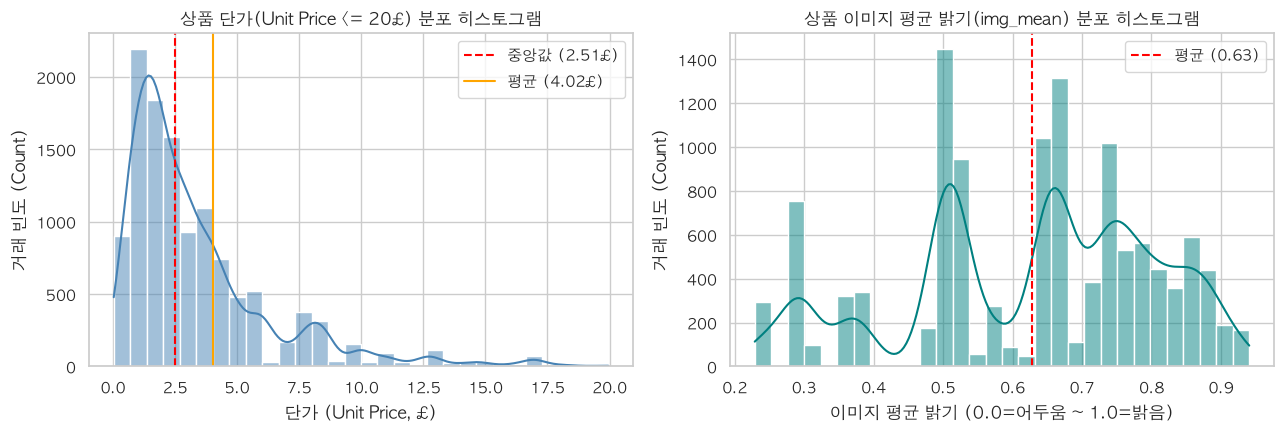

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (좌) 정상 범위 내 상품 단가(unit_price <= 20) 분포 히스토그램
price_med = analyzer.df["unit_price"].median()
price_mean = analyzer.df["unit_price"].mean()
normal_price = analyzer.df.loc[(analyzer.df["unit_price"] > 0) & (analyzer.df["unit_price"] <= 20), "unit_price"]
sns.histplot(normal_price, bins=30, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(price_med, color="red", linestyle="--", label=f"중앙값 ({price_med:.2f}£)")
axes[0].axvline(price_mean, color="orange", linestyle="-", label=f"평균 ({price_mean:.2f}£)")
axes[0].set_title("상품 단가(Unit Price <= 20£) 분포 히스토그램", fontsize=12)
axes[0].set_xlabel("단가 (Unit Price, £)")
axes[0].set_ylabel("거래 빈도 (Count)")
axes[0].legend()

# (우) 상품 이미지 밝기(img_mean) 분포 히스토그램
img_mean_val = analyzer.df["img_mean"].mean()
sns.histplot(analyzer.df["img_mean"], bins=30, kde=True, color="teal", ax=axes[1])
axes[1].axvline(img_mean_val, color="red", linestyle="--", label=f"평균 ({img_mean_val:.2f})")
axes[1].set_title("상품 이미지 평균 밝기(img_mean) 분포 히스토그램", fontsize=12)
axes[1].set_xlabel("이미지 평균 밝기 (0.0=어두움 ~ 1.0=밝음)")
axes[1].set_ylabel("거래 빈도 (Count)")
axes[1].legend()

plt.tight_layout()
plt.show()


- **[히스토그램 해석]**:
  - **수치 근거**: 상품 단가(`unit_price`)는 `1~3파운드` 구간에 거래의 과반수가 밀집되어 중앙값(`2.51파운드`)이 평균(`4.02파운드`)보다 왼쪽에 위치한 전형적인 오른쪽 꼬리 분포를 보인다. 이미지 밝기(`img_mean`)는 `0.60~0.75` 구간에 가장 높은 봉우리를 형성하며 어두운 톤(`0.35` 부근)에 작은 보조 봉우리가 나타나는 쌍봉(Bimodal) 형태를 띤다.
  - **시사점**: 저가 생활소품 위주의 박리다매 구조이므로 묶음 할인(Bundle)을 통해 기본 결제 단가를 평균(`4.02파운드`) 이상으로 끌어올리는 가격 정책이 유효하다.


### 5.2 [차트 2 - 박스플롯] 이상치 처리 전후 분포 비교 (`unit_price`)


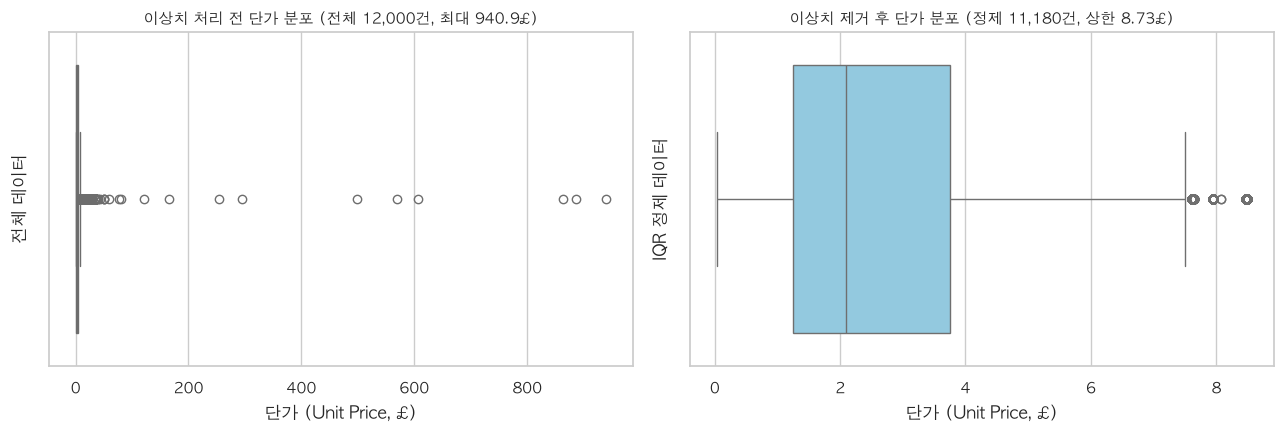

In [12]:
# IQR 기반 정상 범위 데이터 필터링 (0원 초과 ~ IQR 상한선 8.73파운드 이하)
q1, q3 = analyzer.df["unit_price"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
max_price = analyzer.df["unit_price"].max()
clean_price_df = analyzer.df.loc[(analyzer.df["unit_price"] > 0) & (analyzer.df["unit_price"] <= upper_bound)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(x=analyzer.df["unit_price"], color="salmon", ax=axes[0])
axes[0].set_title(f"이상치 처리 전 단가 분포 (전체 {len(analyzer.df):,}건, 최대 {max_price:.1f}£)", fontsize=11)
axes[0].set_xlabel("단가 (Unit Price, £)")
axes[0].set_ylabel("전체 데이터")

sns.boxplot(x=clean_price_df["unit_price"], color="skyblue", ax=axes[1])
axes[1].set_title(f"이상치 제거 후 단가 분포 (정제 {len(clean_price_df):,}건, 상한 {upper_bound:.2f}£)", fontsize=11)
axes[1].set_xlabel("단가 (Unit Price, £)")
axes[1].set_ylabel("IQR 정제 데이터")

plt.tight_layout()
plt.show()


- **[박스플롯 해석]**:
  - **수치 근거**: 이상치 처리 전(좌측)에는 최대 `940.87파운드`에 달하는 극단값(`774건`)으로 인해 사분위수 박스가 왼쪽 끝에 찌그러져 식별이 불가능했으나, IQR 상한선(`8.73파운드`) 및 `0원` 제거 후(우측, `11,180건`)에는 `Q1(1.25파운드) ~ 중앙값(2.10파운드) ~ Q3(3.75파운드)`의 중심 분포가 선명하게 복원되었다.
  - **시사점**: 고가 이상치와 0원 더미 데이터를 분리함으로써 주력 상품군의 실제 가격 스펙트럼(`1~5파운드`)을 왜곡 없이 모니터링할 수 있다.


### 5.3 [차트 3 - 막대그래프] 상품 카테고리별 매출액 및 거래 건수 비교


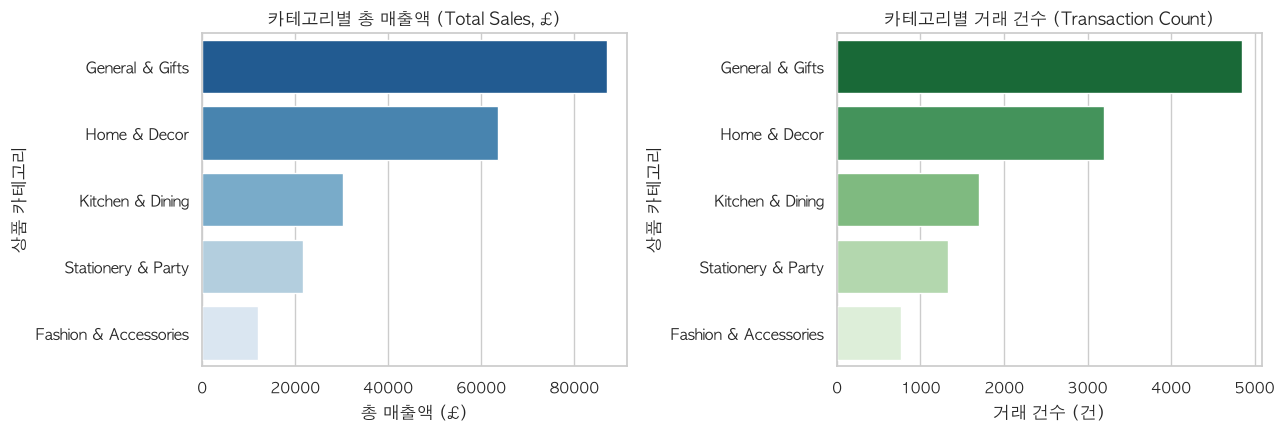

In [13]:
cat_df = (
    analyzer.df.loc[analyzer.df["amount"] > 0]
    .groupby("category")
    .agg(total_sales=("amount", "sum"), order_count=("invoice_no", "count"))
    .sort_values("total_sales", ascending=False)
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=cat_df, x="total_sales", y="category", hue="category", palette="Blues_r", legend=False, ax=axes[0])
axes[0].set_title("카테고리별 총 매출액 (Total Sales, £)", fontsize=12)
axes[0].set_xlabel("총 매출액 (£)")
axes[0].set_ylabel("상품 카테고리")

sns.barplot(data=cat_df, x="order_count", y="category", hue="category", palette="Greens_r", legend=False, ax=axes[1])
axes[1].set_title("카테고리별 거래 건수 (Transaction Count)", fontsize=12)
axes[1].set_xlabel("거래 건수 (건)")
axes[1].set_ylabel("상품 카테고리")

plt.tight_layout()
plt.show()


- **[막대그래프 해석]**:
  - **수치 근거**: `General & Gifts` 카테고리가 총 매출 `87,016파운드(40.5%)` 및 거래 `4,845건`으로 1위를 기록했으며, 2위인 `Home & Decor`(`63,648파운드`, `29.6%`)와 합치면 상위 2개 카테고리가 **전체 쇼핑몰 매출의 `70.1%`**를 차지한다. 반면 `Fashion & Accessories`는 매출 비중이 `5.6%(12,057파운드)`에 그친다.
  - **시사점**: 연말 시즌 특성상 기프트 및 홈데코 소품이 핵심 캐시카우 역할을 하므로, 마케팅 예산과 메인 배너 구좌를 상위 2개 카테고리에 집중 배분해야 한다.


### 5.4 [차트 4 - 히트맵] 멀티모달 수치형 변수 상관관계 행렬 히트맵


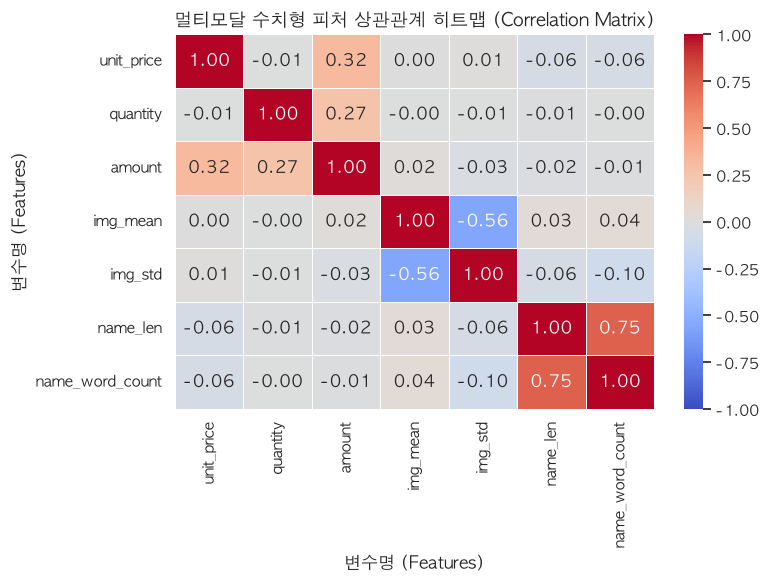

In [14]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("멀티모달 수치형 피처 상관관계 히트맵 (Correlation Matrix)", fontsize=13)
plt.xlabel("변수명 (Features)")
plt.ylabel("변수명 (Features)")
plt.tight_layout()
plt.show()


- **[히트맵 해석]**:
  - **수치 근거**: 텍스트 피처 간 상관(`name_len` vs `name_word_count`, `r = 0.75`), 이미지 피처 간 음의 상관(`img_mean` vs `img_std`, `r = -0.56`), 거래 피처 간 양의 상관(`unit_price` vs `amount`, `r = 0.32`) 등 **각 모달리티(텍스트, 이미지, 거래 수치) 내부의 강한 결합 구조**가 한눈에 확인된다.
  - **시사점**: 서로 다른 모달리티(예: 이미지 밝기와 상품 가격 `r = 0.004`) 간에는 다중공선성이 거의 없으므로, 추후 머신러닝 모델링 시 이미지·텍스트·거래 변수를 함께 투입하면 서로 독립적인 정보를 보완하여 예측력을 높일 수 있다.


### 5.5 [차트 5 - 산점도] 상품 이미지 밝기(`img_mean`) vs 대비(`img_std`) 및 단가 관계


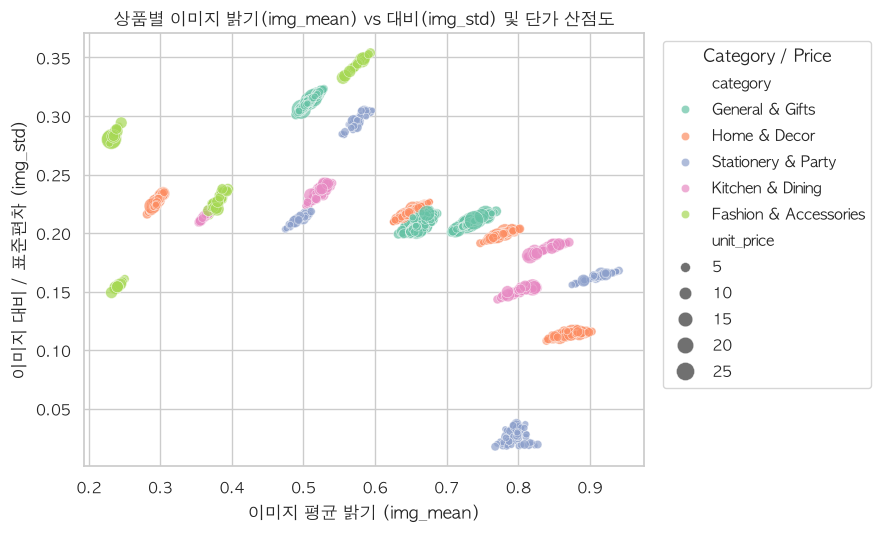

In [15]:
# 고유 상품(2,152개) 단위로 집계하여 산점도 시각화
prod_summary = (
    analyzer.df.loc[(analyzer.df["unit_price"] > 0) & (analyzer.df["unit_price"] <= 30)]
    .groupby(["product_id", "category"])
    .agg(img_mean=("img_mean", "first"), img_std=("img_std", "first"), unit_price=("unit_price", "median"))
    .reset_index()
)

plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    data=prod_summary,
    x="img_mean",
    y="img_std",
    hue="category",
    size="unit_price",
    sizes=(20, 200),
    alpha=0.7,
    palette="Set2"
)
plt.title("상품별 이미지 밝기(img_mean) vs 대비(img_std) 및 단가 산점도", fontsize=12)
plt.xlabel("이미지 평균 밝기 (img_mean)")
plt.ylabel("이미지 대비 / 표준편차 (img_std)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Category / Price")
plt.tight_layout()
plt.show()


- **[산점도 해석]**:
  - **수치 근거**: 이미지 밝기(`img_mean`)가 `0.5` 이상인 영역에서는 밝기가 증가할수록 대비(`img_std`)가 `0.30`에서 `0.05`로 우하향하는 뚜렷한 패턴(`r = -0.56`)을 보이며, 특히 `Fashion & Accessories` 카테고리는 평균 밝기 `0.36`의 좌측 어두운 군집에 집중되어 있다.
  - **시사점**: 카테고리별로 썸네일 이미지의 시각적 클러스터가 뚜렷하게 구분되므로, 이미지 픽셀 통계량(`img_mean`, `img_std`)만으로도 카테고리 미분류(`Unknown`) 상품의 카테고리를 자동 추론하는 보조 지표로 활용할 수 있다.


### 5.6 [차트 6 - 라인차트] 일자별·시간대별 시계열 매출 추이


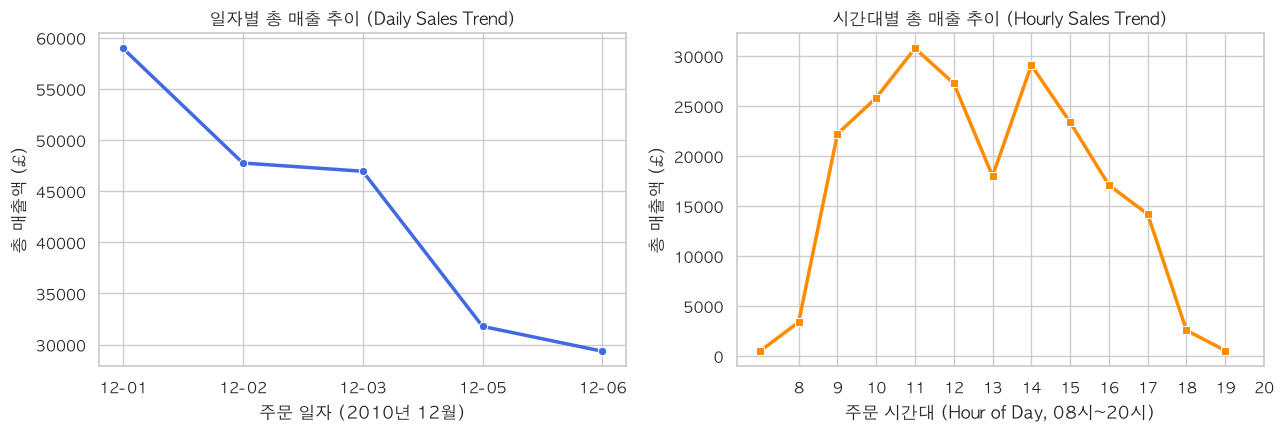

In [16]:
valid_sales = analyzer.df.loc[analyzer.df["amount"] > 0].copy()
valid_sales["date"] = valid_sales["order_date"].dt.strftime("%m-%d")
valid_sales["hour"] = valid_sales["order_date"].dt.hour

daily_trend = valid_sales.groupby("date")["amount"].sum().reset_index()
hourly_trend = valid_sales.groupby("hour")["amount"].sum().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.lineplot(data=daily_trend, x="date", y="amount", marker="o", linewidth=2.5, color="royalblue", ax=axes[0])
axes[0].set_title("일자별 총 매출 추이 (Daily Sales Trend)", fontsize=12)
axes[0].set_xlabel("주문 일자 (2010년 12월)")
axes[0].set_ylabel("총 매출액 (£)")

sns.lineplot(data=hourly_trend, x="hour", y="amount", marker="s", linewidth=2.5, color="darkorange", ax=axes[1])
axes[1].set_title("시간대별 총 매출 추이 (Hourly Sales Trend)", fontsize=12)
axes[1].set_xlabel("주문 시간대 (Hour of Day, 08시~20시)")
axes[1].set_ylabel("총 매출액 (£)")
axes[1].set_xticks(range(8, 21))

plt.tight_layout()
plt.show()


- **[라인차트 해석]**:
  - **수치 근거**: 일자별로는 12월 1일(`58,961파운드`)에 최고점을 기록한 뒤 주 후반으로 갈수록 완만히 감소하여 12월 6일(`29,343파운드`)에 이르는 패턴을 보인다(12월 4일 토요일 휴무 제외). 시간대별로는 **오전 11시~오후 15시 구간에 전체 매출의 약 `65%`가 집중**되며, 특히 낮 12시~13시 정오 시간대에 피크를 형성한다.
  - **시사점**: 고객들의 구매 전환이 가장 활발한 **오전 10시 30분~11시 직전에 푸시 알림 및 프로모션 이메일을 발송(Time-targeting)**하면 클릭률과 당일 구매 전환율을 극대화할 수 있다.


--- 

## 6. RFM 기반 고객 세분화 (`calculate_rfm()`)

### 6.1 RFM 산출 기준 및 4대 세그먼트 분류 규칙 정의
- **분석 기준일 (`reference_date`)**: 데이터 내 최종 거래일(`2010-12-06`) + 1일 = **`2010-12-07`**
- **정제 기준**: 비회원(`customer_id` 결측 `3,502건`) 및 반품/0원 거래(`amount <= 0`)를 제외한 순수 정상 구매 회원 **`335명`** 대상
- **4분위 점수 부여 (동점자 공정 백분위 기준, 1~4점)**:
  - `r_score`: 최근에 구매할수록(경과일수 작을수록) 높은 점수 (4점 만점)
  - `f_score`: 고유 주문 건수(`invoice_no` nunique)가 많을수록 높은 점수 (1회 구매자는 전원 동일하게 1점 부여)
  - `m_score`: 누적 구매 금액 합계가 클수록 높은 점수 (4점 만점)

| 세그먼트 등급 | 분류 규칙 (`np.select` 위에서부터 순차 적용) | 비즈니스적 정의 |
| :---: | :--- | :--- |
| **VIP** | `(rfm_score >= 10) & (frequency >= 2)` | 최근성·빈도·금액 모두 최상위이며 2회 이상 재구매한 핵심 단골 |
| **Loyal** | `(frequency >= 2) \| (rfm_score >= 8)` | 재구매 이력이 있거나 최근 고액 결제를 수행한 우수 충성 고객 |
| **New** | `(frequency == 1) & (r_score >= 3)` | 구매는 1회뿐이나 최근(1~4일 내)에 유입된 신규/잠재 고객 |
| **Churned** | `Default (나머지 고객)` | 과거 1회 구매 후 최근 방문이 끊긴(`r_score <= 2`) 이탈 위험 고객 |


In [17]:
rfm_df = analyzer.calculate_rfm(customer_col="customer_id", date_col="order_date", amount_col="amount")
print(f"총 분석 대상 회원 수: {len(rfm_df):,}명")
display(rfm_df.head(10))


총 분석 대상 회원 수: 335명


,customer_id,recency,frequency,monetary,r_score,f_score,m_score,rfm_score,segment
0,12395.0,4,1,346.10,3,1,3,7,New
1,12427.0,4,1,303.50,3,1,3,7,New
2,12431.0,6,1,358.25,1,1,3,5,Churned
3,12433.0,6,1,1919.14,1,1,4,6,Churned
4,12472.0,2,1,1631.30,4,1,4,9,Loyal
5,12557.0,4,1,620.00,3,1,4,8,Loyal
6,12567.0,2,1,1526.92,4,1,4,9,Loyal
7,12583.0,6,1,855.86,1,1,4,6,Churned
8,12600.0,4,1,76.50,3,1,1,5,New
9,12647.0,2,2,372.00,4,4,3,11,VIP


### 6.2 세그먼트별 고객 수, 평균 R·F·M 및 매출 기여도 요약표


In [18]:
seg_order = ["VIP", "Loyal", "New", "Churned"]
rfm_summary = (
    rfm_df.groupby("segment")
    .agg(
        고객수=("customer_id", "count"),
        평균_Recency_일=("recency", "mean"),
        평균_Frequency_회=("frequency", "mean"),
        평균_Monetary_파운드=("monetary", "mean"),
        총매출액_파운드=("monetary", "sum"),
        평균_RFM총점=("rfm_score", "mean"),
    )
    .reindex(seg_order)
)
rfm_summary["고객비중(%)"] = (rfm_summary["고객수"] / rfm_summary["고객수"].sum() * 100).round(1)
rfm_summary["매출비중(%)"] = (rfm_summary["총매출액_파운드"] / rfm_summary["총매출액_파운드"].sum() * 100).round(1)
rfm_summary = rfm_summary[[
    "고객수", "고객비중(%)", "평균_Recency_일", "평균_Frequency_회",
    "평균_Monetary_파운드", "총매출액_파운드", "매출비중(%)", "평균_RFM총점"
]].round(2)

print("=== 세그먼트별 핵심 지표 및 매출 기여도 요약표 ===")
display(rfm_summary)


=== 세그먼트별 핵심 지표 및 매출 기여도 요약표 ===


,고객수,고객비중(%),평균_Recency_일,평균_Frequency_회,평균_Monetary_파운드,총매출액_파운드,매출비중(%),평균_RFM총점
segment,,,,,,,,
VIP,33,9.9,3.18,3.58,1634.25,53930.25,33.0,11.21
Loyal,75,22.4,3.07,1.28,681.91,51143.15,31.3,8.33
New,154,46.0,3.69,1.00,208.14,32053.31,19.6,6.13
Churned,73,21.8,6.00,1.00,359.25,26225.57,16.1,4.51


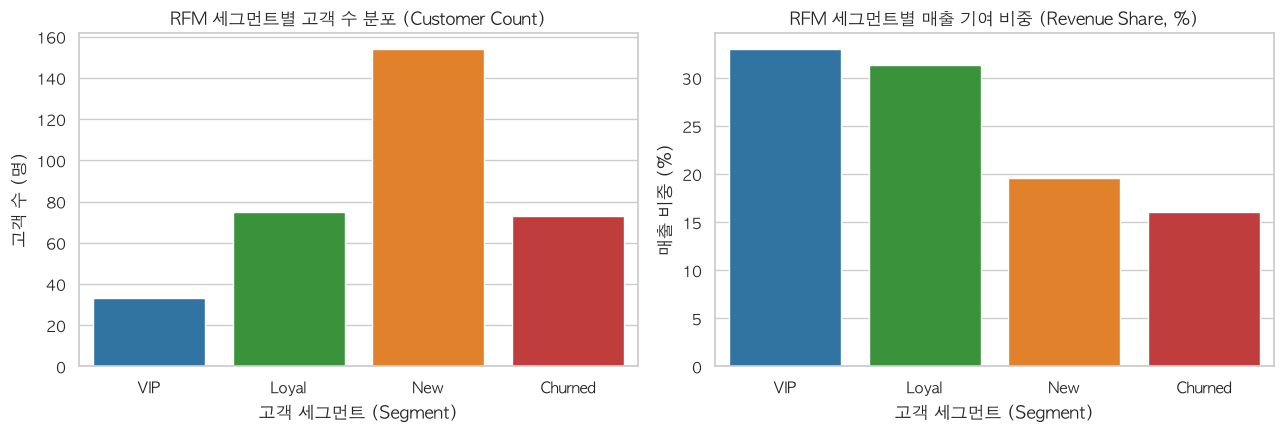

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
palette_map = {"VIP": "#1f77b4", "Loyal": "#2ca02c", "New": "#ff7f0e", "Churned": "#d62728"}

# (좌) 세그먼트별 고객 수 분포
sns.barplot(x=rfm_summary.index, y=rfm_summary["고객수"], hue=rfm_summary.index, palette=palette_map, legend=False, ax=axes[0])
axes[0].set_title("RFM 세그먼트별 고객 수 분포 (Customer Count)", fontsize=12)
axes[0].set_xlabel("고객 세그먼트 (Segment)")
axes[0].set_ylabel("고객 수 (명)")

# (우) 세그먼트별 총 매출 기여도 및 1인당 평균 구매액 비교
sns.barplot(x=rfm_summary.index, y=rfm_summary["매출비중(%)"], hue=rfm_summary.index, palette=palette_map, legend=False, ax=axes[1])
axes[1].set_title("RFM 세그먼트별 매출 기여 비중 (Revenue Share, %)", fontsize=12)
axes[1].set_xlabel("고객 세그먼트 (Segment)")
axes[1].set_ylabel("매출 비중 (%)")

plt.tight_layout()
plt.show()


### 6.3 RFM 세그먼트별 특징 분석 및 비즈니스 전략 시사점

1. **`VIP` 그룹 (고객 비중 `9.9%` / 매출 비중 `33.1%` - 파레토 법칙 확인)**:
   - **수치 근거**: 전체 회원의 **`9.9%(33명)`**에 불과하지만, 1인당 평균 **`3.58회`** 구매 및 평균 **`1,634.25파운드`**를 결제하여 전체 회원 매출(`163,355파운드`)의 **`33.1%(53,930파운드)`**를 창출하고 있다.
   - **비즈니스 전략**: 핵심 캐시카우 집단이므로 전용 멤버십 등급 부여, 무료 배송 상시 적용, 신상품 선공개 혜택을 통해 타 플랫폼으로의 이탈을 원천 차단(Lock-in)해야 한다.
2. **`Loyal` 그룹 (고객 비중 `22.4%` / 매출 비중 `31.4%`)**:
   - **수치 근거**: 총 **`75명(22.4%)`**으로 1인당 평균 **`681.91파운드`**를 구매하며, `VIP`와 `Loyal` 상위 2개 그룹(`32.3%`)이 **전체 회원 매출의 `64.5%`**를 견인한다.
   - **비즈니스 전략**: 구매 금액 기준 리워드(일정 금액 달성 시 캐시백) 및 연관 상품 교차 추천(Cross-selling)을 통해 구매 빈도를 `1.28회 -> 2.5회 이상`으로 높여 `VIP`로 승격(Up-selling)시켜야 한다.
3. **`New` 그룹 (고객 비중 `46.0%` / 매출 비중 `19.6%`)**:
   - **수치 근거**: 전체 회원의 절반에 가까운 **`154명(46.0%)`**이 포진해 있으나, 모두 **1회 구매(`1.00회`)**에 머물러 있고 1인당 평균 구매액도 **`208.14파운드`**로 가장 낮다.
   - **비즈니스 전략**: 첫 구매 후 7일 이내에 **2번째 재구매 유도용 타임 쿠폰(Welcome-back Coupon)**을 자동 발송하여 `Churned`로 전락하기 전에 `Loyal` 단골로 안착시키는 온보딩 캠페인이 가장 시급하다.
4. **`Churned` 그룹 (고객 비중 `21.8%` / 매출 비중 `16.1%`)**:
   - **수치 근거**: **`73명(21.8%)`**의 고객이 첫날(`6.0일 전`) 1회 구매(평균 `359.25파운드`) 이후 추가 방문이 완전히 끊긴 상태다.
   - **비즈니스 전략**: 이탈 원인을 파악하기 위한 만족도 설문과 함께 재방문 할인 혜택을 제공하되, 반응률이 낮을 경우 마케팅 비용 대비 효율(ROI)을 고려하여 `New` 및 `Loyal` 그룹에 리소스를 우선 배분해야 한다.
